# Case 2: Early diabetic retinopathy

*Hands-On Electroretinography in the Age of AI*, Chapter 19, §19.2.

Mr. K. is in the 36 to 59y age stratum. His recording passes the signal quality check (DTL Plus, SNR 11.2 for DA 3.0 and 13.4 for LA 30 Hz). This notebook assigns the Traffic Light zones of Table 19.2 with the pipeline code and checks both the zones and the printed limits against the book. It then lists the Level 1 SHAP contributions of Table 19.3.

The values are constructed for teaching; they are not patient data. Limits: Baker et al. (2025), silver thread, 36 to 59y.

**Setup.** In Google Colab, the first cell clones the repository. Elsewhere, run the notebook from the repository.

In [1]:
import os, sys
if 'google.colab' in sys.modules and not os.path.exists('/content/ERG-Analysis-API'):
    !git clone -q https://github.com/AI-Fairness-com/ERG-Analysis-API.git /content/ERG-Analysis-API
sys.path.insert(0, '/content/ERG-Analysis-API/examples')
sys.path.insert(0, os.path.abspath('examples') if os.path.isdir('examples') else os.getcwd())
from case_helpers import zone_table, check, REPORT

**Table 19.2 values.** Each row: protocol, parameter, value, the zone printed in the book and the limits printed in the book. The PhNR and the OP values have no published limits.

In [2]:
ROWS = [
    ('DA 0.01', 'b-wave amplitude',      175,  'GREEN', (115, 279)),
    ('DA 0.01', 'b-wave implicit time',  98.6, 'GREEN', (77.5, 107.5)),
    ('DA 3.0',  'a-wave amplitude',      150,  'GREEN', (100, 226)),
    ('DA 3.0',  'a-wave implicit time',  17.3, 'AMBER', (14.5, 17)),
    ('DA 3.0',  'b-wave amplitude',      240,  'GREEN', (167, 377)),
    ('DA 3.0',  'b-wave implicit time',  49.8, 'GREEN', (46.5, 59.5)),
    ('DA 10.0', 'a-wave amplitude',      180,  'GREEN', (124, 277)),
    ('DA 10.0', 'a-wave implicit time',  15.6, 'AMBER', (11, 15)),
    ('DA 10.0', 'b-wave amplitude',      280,  'GREEN', (191, 387)),
    ('DA 10.0', 'b-wave implicit time',  52,   'GREEN', (47, 59.5)),
    ('LA 3.0',  'a-wave amplitude',      22,   'GREEN', (13, 40)),
    ('LA 3.0',  'a-wave implicit time',  14.2, 'GREEN', (13, 15.5)),
    ('LA 3.0',  'b-wave amplitude',      100,  'GREEN', (64, 172)),
    ('LA 3.0',  'b-wave implicit time',  29.4, 'GREEN', (27, 31.5)),
    ('LA 30 Hz', 'flicker amplitude',    75,   'GREEN', (45, 140)),
    ('LA 30 Hz', 'flicker implicit time', 27.9, 'GREEN', (24, 29.5)),
    ('LA 3.0',  'PhNR amplitude',        31.4, 'Not zoned'),
    ('DA 3.0',  'OP2 amplitude',         14,   'Not zoned'),
    ('DA 3.0',  'OP3 amplitude',         9,    'Not zoned'),
    ('DA 3.0',  'Summed OP amplitude',   36,   'Not zoned'),
]

**Zones.** Fourteen of the sixteen zoned values are GREEN. The two AMBER a-wave implicit times make the composite Traffic Light AMBER, which on its own prompts only a clinical review (Chapter 10 §10.4).

In [3]:
table, signal = zone_table(ROWS, age=48)
print(table.drop(columns='Match').to_string(index=False))
print('\nComposite Traffic Light:', signal)
check(table)

Protocol             Parameter  Value                              Limits Zone (code) Zone (book)
 DA 0.01      b-wave amplitude  175.0     115 to 279 (L_lo 102, U_hi 315)       GREEN       GREEN
 DA 0.01  b-wave implicit time   98.6 77.5 to 107.5 (L_lo 73, U_hi 118.5)       GREEN       GREEN
  DA 3.0      a-wave amplitude  150.0      100 to 226 (L_lo 90, U_hi 239)       GREEN       GREEN
  DA 3.0  a-wave implicit time   17.3   14.5 to 17 (L_lo 14.5, U_hi 17.5)       AMBER       AMBER
  DA 3.0      b-wave amplitude  240.0     167 to 377 (L_lo 163, U_hi 469)       GREEN       GREEN
  DA 3.0  b-wave implicit time   49.8   46.5 to 59.5 (L_lo 45, U_hi 59.5)       GREEN       GREEN
 DA 10.0      a-wave amplitude  180.0     124 to 277 (L_lo 118, U_hi 384)       GREEN       GREEN
 DA 10.0  a-wave implicit time   15.6     11 to 15 (L_lo 10.5, U_hi 16.5)       AMBER       AMBER
 DA 10.0      b-wave amplitude  280.0     191 to 387 (L_lo 171, U_hi 481)       GREEN       GREEN
 DA 10.0  b-wave imp

**Level 1 SHAP contributions (Table 19.3).** These values are constructed for teaching, because the classifier has not been trained yet. The contributions add up from the base value of 0.14 to the model output of 0.68 (local accuracy, Chapter 14).

In [4]:
import pandas as pd
shap = pd.DataFrame([
    ('OP2 amplitude (14 µV)',              +0.19),
    ('OP energy near 80 Hz (0.8 µV²)',     +0.15),
    ('DA 3.0 a-wave time (17.3 ms)',       +0.11),
    ('Summed OP amplitude (36 µV)',        +0.09),
    ('DA 3.0 b-wave amplitude (240 µV)',   -0.08),
    ('OP3 amplitude (9 µV)',               +0.06),
    ('DA 0.01 b-wave amplitude (175 µV)',  -0.05),
    ('All other features',                 +0.07),
], columns=['Feature (measured value)', 'SHAP value'])
shap['Direction'] = shap['SHAP value'].map(
    lambda v: 'Toward DR' if v > 0 else 'Away from DR')
print(shap.to_string(index=False))
base, total = 0.14, shap['SHAP value'].sum()
print(f'\nBase {base} + total {total:+.2f} = output {base + total:.2f}')
assert round(base + total, 2) == 0.68

         Feature (measured value)  SHAP value    Direction
            OP2 amplitude (14 µV)        0.19    Toward DR
   OP energy near 80 Hz (0.8 µV²)        0.15    Toward DR
     DA 3.0 a-wave time (17.3 ms)        0.11    Toward DR
      Summed OP amplitude (36 µV)        0.09    Toward DR
 DA 3.0 b-wave amplitude (240 µV)       -0.08 Away from DR
             OP3 amplitude (9 µV)        0.06    Toward DR
DA 0.01 b-wave amplitude (175 µV)       -0.05 Away from DR
               All other features        0.07    Toward DR

Base 0.14 + total +0.54 = output 0.68


**Waterfall chart (Figure 19.2).** Each bar starts where the previous one ended. Coral bars push toward Diabetic Retinopathy and teal bars push away.

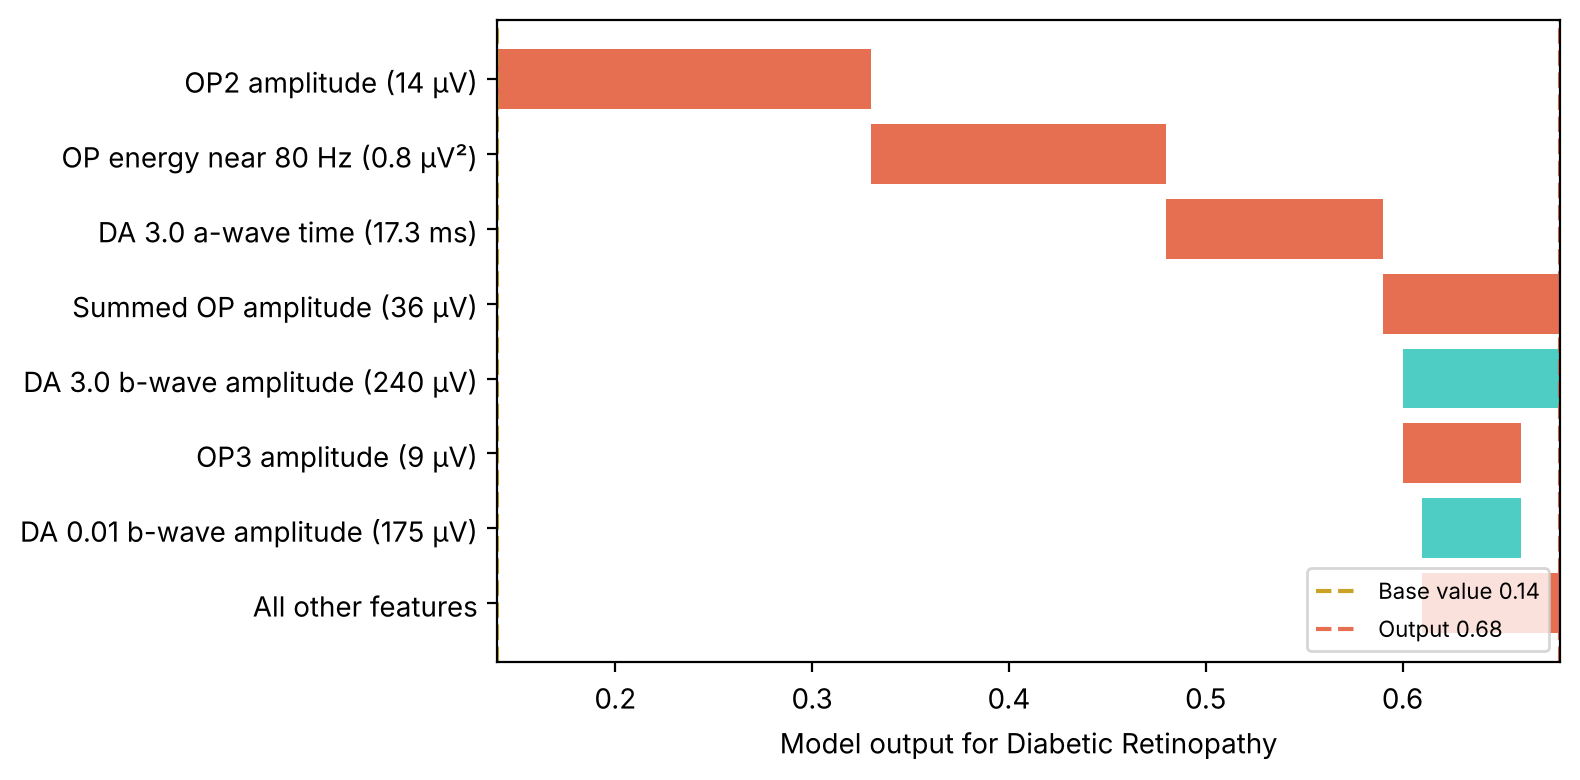

In [5]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 4))
start = base
for i, (name, v) in enumerate(zip(shap['Feature (measured value)'], shap['SHAP value'])):
    ax.barh(i, v, left=start, color='#e76f51' if v > 0 else '#4ecdc4')
    start += v
ax.axvline(base, color='#c9a227', linestyle='--', label=f'Base value {base}')
ax.axvline(start, color='#e76f51', linestyle='--', label=f'Output {start:.2f}')
ax.set_yticks(range(len(shap)), shap['Feature (measured value)'])
ax.invert_yaxis()
ax.set_xlabel('Model output for Diabetic Retinopathy')
ax.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()